# E3a: ¿cómo se calcula la feature de acoplamiento F? (y E4: la mejor HRV)

**Preguntas.** (E3a) Entre todas las formas razonables de convertir el acoplamiento RR–EDR en un número por minuto, ¿cuáles separan mejor los minutos con y sin apnea? (E4) ¿Cuál es la mejor feature de HRV con la misma métrica? Esa es la referencia contra la que compite F en H2.

**Diseño original (fijado antes de la primera corrida).**
- **Datos:** los 47 registros de desarrollo (19 sujetos). Test no se usa. Minutos con etiqueta, con 20 % o menos de RR corregidos y con todas las candidatas calculables (la ventana de 8,5 min recorta los bordes de la noche), así todas se comparan sobre los mismos minutos.
- **Candidatas de acoplamiento:** EDR (área, deriva, combinado) × ventana (3, 4, 5, 6, 7, 8,5 min) × estimador (Welch con 3 segmentos, Welch con 7, multitaper NW = 2) × bandas (CPC 0,01–0,1 / 0,1–0,4; v2 0,01–0,15 / 0,15–0,4; apnea 0,01–0,05 / 0,15–0,4) × forma. Sin normalizar ni suavizar: eso es E3b.
- **Candidatas de HRV (60):** ventana (las mismas 6) × feature (RR medio, SDNN, RMSSD, pNN50 y, con Lomb, potencia en la banda de apnea, VLF, LF, HF, total y LF/HF).
- **Sentido:** cada candidata se orienta para que "más alto = más apnea", con los datos de elección.
- **Regla:** (1) AUC por minuto con todos los minutos juntos, bootstrap por sujeto; grupo de candidatas equivalentes a la mejor; (2) dentro del grupo, acierto por registro (Spearman entre la fracción de apnea estimada con el umbral de Youden y la real); (3) la más simple. Orden de simplicidad: estimador (Welch 3 < Welch 7 < multitaper), forma (en el orden de la lista), ventana más corta, bandas (CPC < v2 < apnea), EDR (deriva < área < combinado); para HRV, feature y ventana más corta.
- **¿Es azar?** Validación cruzada: 5 grupos de sujetos (separando sujetos con y sin apnea); con 4 se elige y se mide en el que quedó afuera. Optimismo, estabilidad y comparación con una referencia fija (la configuración publicada que usó E2: área, 8,5 min, Welch 3, bandas CPC, log-cociente).

**Versión 2: desvíos declarados después de la primera corrida.**
1. **Regla de equivalencia.** En la regla original el grupo era "el IC de la diferencia con la mejor incluye 0". Eso resultó defectuoso: que no se pueda probar que una candidata es peor no significa que sea igual de buena, y la regla mete a las candidatas **ruidosas** (IC ancho) y deja afuera a las **parecidas** (IC angosto). En la primera corrida eligió una candidata con AUC 0,825 dejando afuera otras de 0,850, y en un grupo de la validación cruzada de HRV eligió el RR medio con AUC 0,51. Se agregan dos reglas, fijadas antes de ver qué eligen:
   - **B (no inferioridad):** el grupo son las candidatas que, con 95 % de confianza, son como mucho δ = 0,02 de AUC peores que la mejor.
   - **C (mayor AUC):** solo la mejor, sin desempate.
   **Cuál se usa lo decide la validación cruzada:** gana la regla con mayor AUC promedio en los sujetos que quedan afuera; si la diferencia es menor a 0,01 se considera empate y se usa B (su configuración final es más simple). La regla original se sigue reportando.
2. **Forma agregada: "potencia sola"** (log de la potencia cruzada en la banda lenta, sin coherencia). Es un control para saber si la coherencia aporta algo más que la potencia que comparten RR y EDR. Entra también en la elección. Quedan 7 formas y 1.134 candidatas de acoplamiento.

In [1]:
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["PYTHONPATH"] = str(ROOT)                       # para los procesos en paralelo
from src.config import RESULTS_DIR, SPLIT_CSV
from src.features.build import record_feature_tables
from src.features.variants import BANDS, coupling_variants, hrv_variants
from src.stats.compare import (compare_variants, cross_validate_selection, pooled_auc,
                               select_variant, subject_folds)

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS_DIR / "e3"; CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"

split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
WIDTHS = (180, 240, 300, 360, 420, 512)
ESTIMATORS = ("welch3", "welch7", "multitaper")
EDRS = ("area", "baseline", "combined")
REFERENCIA = "area|512s|welch3|CPC|log-cociente"
REGLAS = {"original": "original", "B (no inferioridad 0,02)": "noninferior", "C (mayor AUC)": "max"}
print(f"{len(DEV)} registros de desarrollo, {split.loc[DEV, 'subject'].nunique()} sujetos")

47 registros de desarrollo, 19 sujetos


In [2]:
f_coup, f_hrv = CACHE / "acoplamiento.parquet", CACHE / "hrv.parquet"
if f_coup.exists() and f_hrv.exists():
    coup, hrv = pd.read_parquet(f_coup), pd.read_parquet(f_hrv)
else:
    with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
        res = list(ex.map(record_feature_tables, DEV, [WIDTHS] * len(DEV), [ESTIMATORS] * len(DEV),
                          [EDRS] * len(DEV), [BANDS] * len(DEV)))
    coup = pd.concat([r[0] for r in res], ignore_index=True)
    hrv = pd.concat([r[1] for r in res], ignore_index=True)
    coup.to_parquet(f_coup); hrv.to_parquet(f_hrv)
print(f"filas: acoplamiento {len(coup):,} | HRV {len(hrv):,}")

filas: acoplamiento 1,233,495 | HRV 137,078


In [3]:
wide_c, meta_c = coupling_variants(coup)
wide_h, meta_h = hrv_variants(hrv)
info = (coup[(coup.edr == "area") & (coup.window == 512) & (coup.estimator == "welch3")]
        .set_index(["record", "minute"])[["label", "corrected"]])
idx = (wide_c.dropna().index.intersection(wide_h.dropna().index)
       .intersection(info.index[(info.label >= 0) & (info.corrected <= 0.2)]))
wide_c, wide_h, info = wide_c.loc[idx], wide_h.loc[idx], info.loc[idx]
y = info.label.to_numpy().astype(int)
recs = idx.get_level_values("record").to_numpy()
subj = split.loc[recs, "subject"].to_numpy()
print(f"candidatas: acoplamiento {wide_c.shape[1]} | HRV {wide_h.shape[1]}")
print(f"minutos comunes: {len(idx):,} ({y.mean():.1%} con apnea) | registros {len(set(recs))} | sujetos {len(set(subj))}")

candidatas: acoplamiento 1134 | HRV 60
minutos comunes: 22,123 (39.9% con apnea) | registros 47 | sujetos 19


## Elección con todos los sujetos de desarrollo, con cada regla

In [4]:
sel_c = {nombre: select_variant(wide_c, y, subj, recs, meta_c.complejidad, rule=r) for nombre, r in REGLAS.items()}
sel_h = {nombre: select_variant(wide_h, y, subj, recs, meta_h.complejidad, rule=r) for nombre, r in REGLAS.items()}
auc_c = sel_c["C (mayor AUC)"]["auc"].join(meta_c.drop(columns="complejidad"))
auc_h = sel_h["C (mayor AUC)"]["auc"].join(meta_h.drop(columns="complejidad"))
pd.DataFrame([{"regla": n, "familia": fam, "ganadora": s["ganadora"],
               "AUC": (auc_c if fam == "acoplamiento" else auc_h).loc[s["ganadora"], "auc"],
               "tamaño del grupo": len(s["grupo"])}
              for fam, sels in (("acoplamiento", sel_c), ("HRV", sel_h)) for n, s in sels.items()]).round(3)

,regla,familia,ganadora,AUC,tamaño del grupo
0,original,acoplamiento,combined|180s|welch3|CPC|potencia sola,0.828,113
1,"B (no inferioridad 0,02)",acoplamiento,area|180s|welch3|apnea|potencia sola,0.871,17
2,C (mayor AUC),acoplamiento,area|240s|welch3|apnea|potencia sola,0.876,1
3,original,HRV,hrv|180s|apnea,0.812,9
4,"B (no inferioridad 0,02)",HRV,hrv|180s|vlf,0.810,7
5,C (mayor AUC),HRV,hrv|180s|apnea,0.812,1


In [5]:
cols = ["edr", "ventana_s", "estimador", "bandas", "forma", "auc", "ic_lo", "ic_hi", "p_mejor"]
auc_c.sort_values("auc", ascending=False).head(20)[cols].round(3)

,edr,ventana_s,estimador,bandas,forma,auc,ic_lo,ic_hi,p_mejor
area|240s|welch3|apnea|potencia sola,area,240,welch3,apnea,potencia sola,0.876,0.811,0.925,0.424
area|420s|welch3|apnea|potencia sola,area,420,welch3,apnea,potencia sola,0.875,0.807,0.926,0.136
area|420s|welch7|apnea|potencia sola,area,420,welch7,apnea,potencia sola,0.874,0.803,0.928,0.266
area|300s|welch7|apnea|potencia sola,area,300,welch7,apnea,potencia sola,0.872,0.803,0.926,0.001
area|240s|welch7|apnea|potencia sola,area,240,welch7,apnea,potencia sola,0.872,0.806,0.923,0.018
area|420s|multitaper|apnea|potencia sola,area,420,multitaper,apnea,potencia sola,0.871,0.802,0.924,0.000
area|180s|welch3|apnea|potencia sola,area,180,welch3,apnea,potencia sola,0.871,0.806,0.922,0.000
area|512s|multitaper|apnea|potencia sola,area,512,multitaper,apnea,potencia sola,0.871,0.800,0.924,0.000
area|300s|welch3|apnea|potencia sola,area,300,welch3,apnea,potencia sola,0.869,0.802,0.921,0.000
area|240s|multitaper|apnea|potencia sola,area,240,multitaper,apnea,potencia sola,0.869,0.803,0.921,0.000


In [6]:
grupo_b = auc_c.loc[sel_c["B (no inferioridad 0,02)"]["grupo"]]
print(f"Grupo de la regla B: {len(grupo_b)} candidatas")
for f in ["edr", "ventana_s", "estimador", "bandas", "forma"]:
    print(f"  {f}: " + ", ".join(f"{k} {v}" for k, v in grupo_b[f].value_counts().items()))

Grupo de la regla B: 17 candidatas
  edr: area 17
  ventana_s: 240 4, 300 3, 420 3, 512 3, 180 2, 360 2
  estimador: multitaper 6, welch3 6, welch7 5
  bandas: apnea 16, CPC 1
  forma: potencia sola 17


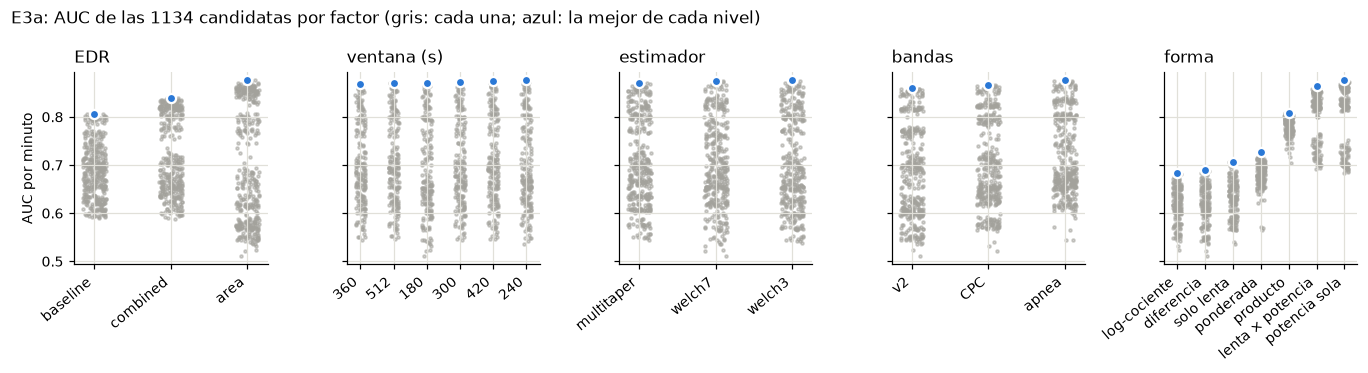

In [7]:
factores = {"edr": "EDR", "ventana_s": "ventana (s)", "estimador": "estimador", "bandas": "bandas", "forma": "forma"}
fig, axes = plt.subplots(1, 5, figsize=(12.5, 3.4), sharey=True)
for ax, (f, titulo) in zip(axes, factores.items()):
    niveles = list(auc_c.groupby(f).auc.max().sort_values().index)
    for i, nv in enumerate(niveles):
        v = auc_c.auc[auc_c[f] == nv]
        ax.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-0.15, 0.15, len(v)), v,
                   s=4, color=GRIS, alpha=0.5)
        ax.scatter(i, v.max(), s=36, color=AZUL, edgecolor="white", linewidth=1.5, zorder=3)
    ax.set_xticks(range(len(niveles)), [str(n) for n in niveles], rotation=40, ha="right")
    ax.set_title(titulo, loc="left")
axes[0].set_ylabel("AUC por minuto")
fig.suptitle(f"E3a: AUC de las {len(auc_c)} candidatas por factor (gris: cada una; azul: la mejor de cada nivel)",
             x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIG / "E3a_factores.png")

## E4: las mejores features de HRV

In [8]:
auc_h["signo"] = sel_h["C (mayor AUC)"]["signos"]
auc_h.sort_values("auc", ascending=False).head(15)[["feature", "ventana_s", "signo", "auc", "ic_lo", "ic_hi", "p_mejor"]].round(3)

,feature,ventana_s,signo,auc,ic_lo,ic_hi,p_mejor
hrv|180s|apnea,apnea,180,1.0,0.812,0.706,0.895,0.614
hrv|180s|vlf,vlf,180,1.0,0.810,0.703,0.893,0.214
hrv|240s|apnea,apnea,240,1.0,0.809,0.700,0.894,0.010
hrv|240s|vlf,vlf,240,1.0,0.807,0.697,0.892,0.002
hrv|300s|apnea,apnea,300,1.0,0.806,0.694,0.893,0.012
hrv|300s|vlf,vlf,300,1.0,0.804,0.691,0.891,0.000
hrv|360s|apnea,apnea,360,1.0,0.803,0.690,0.892,0.000
hrv|360s|vlf,vlf,360,1.0,0.801,0.687,0.889,0.000
hrv|420s|apnea,apnea,420,1.0,0.800,0.686,0.890,0.000
hrv|420s|vlf,vlf,420,1.0,0.798,0.681,0.888,0.000


## Validación cruzada por sujetos: ¿es azar? y ¿qué regla generaliza mejor?

In [9]:
tiene_apnea = pd.Series(y, index=subj).groupby(level=0).max().astype(bool)
folds = subject_folds(tiene_apnea, k=5)
print("sujetos afuera en cada grupo:", [len(f) for f in folds])
cv_c, cv_h = {}, {}
for nombre, r in REGLAS.items():
    cv = cross_validate_selection(wide_c, y, subj, recs, meta_c.complejidad, folds, reference=REFERENCIA,
                                  n_boot=1000, n_boot_rec=300, rule=r)
    cv_c[nombre] = cv.join(meta_c.drop(columns="complejidad"), on="ganadora")
    cv = cross_validate_selection(wide_h, y, subj, recs, meta_h.complejidad, folds,
                                  n_boot=1000, n_boot_rec=300, rule=r)
    cv_h[nombre] = cv.join(meta_h.drop(columns="complejidad"), on="ganadora")
resumen = pd.DataFrame({
    f"{fam}: {n}": {"AUC al elegir": cv["AUC al elegir"].mean(), "AUC afuera": cv["AUC afuera"].mean(),
                    "optimismo": (cv["AUC al elegir"] - cv["AUC afuera"]).mean(),
                    "peor grupo afuera": cv["AUC afuera"].min()}
    for fam, d in (("acoplamiento", cv_c), ("HRV", cv_h)) for n, cv in d.items()}).T
resumen.loc["acoplamiento: referencia fija", "AUC afuera"] = cv_c["original"]["referencia afuera"].mean()
resumen.round(3)

sujetos afuera en cada grupo: [4, 4, 4, 4, 3]


,AUC al elegir,AUC afuera,optimismo,peor grupo afuera
acoplamiento: original,0.859,0.795,0.064,0.524
"acoplamiento: B (no inferioridad 0,02)",0.870,0.850,0.021,0.690
acoplamiento: C (mayor AUC),0.875,0.849,0.026,0.687
HRV: original,0.762,0.666,0.097,0.529
"HRV: B (no inferioridad 0,02)",0.818,0.731,0.088,0.529
HRV: C (mayor AUC),0.820,0.731,0.089,0.527
acoplamiento: referencia fija,NaN,0.596,NaN,NaN


In [10]:
afuera = {n: cv["AUC afuera"].mean() for n, cv in cv_c.items() if n != "original"}
dif = afuera["C (mayor AUC)"] - afuera["B (no inferioridad 0,02)"]
REGLA = "C (mayor AUC)" if dif >= 0.01 else "B (no inferioridad 0,02)"
print(f"AUC afuera: B = {afuera['B (no inferioridad 0,02)']:.3f}, C = {afuera['C (mayor AUC)']:.3f} "
      f"(C - B = {dif:+.3f}) -> regla elegida: {REGLA}")
for n in REGLAS:
    print(f"\n{n}:")
    print(cv_c[n][["edr", "ventana_s", "estimador", "bandas", "forma", "AUC al elegir", "AUC afuera"]].round(3).to_string())

AUC afuera: B = 0.850, C = 0.849 (C - B = -0.000) -> regla elegida: B (no inferioridad 0,02)

original:
            edr  ventana_s estimador bandas          forma  AUC al elegir  AUC afuera
grupo                                                                                
1          area        240    welch3  apnea  potencia sola          0.856       0.949
2          area        180    welch3    CPC  potencia sola          0.868       0.850
3          area        180    welch3    CPC  potencia sola          0.889       0.771
4      combined        180    welch3    CPC  potencia sola          0.867       0.524
5      combined        180    welch3    CPC  potencia sola          0.816       0.882

B (no inferioridad 0,02):
        edr  ventana_s estimador bandas          forma  AUC al elegir  AUC afuera
grupo                                                                            
1      area        180    welch3  apnea  potencia sola          0.851       0.946
2      area        18

## Resultado final y control: ¿aporta la coherencia?

Dentro de la configuración ganadora (mismo EDR, ventana, estimador y bandas) se comparan tres formas y la mejor HRV de la misma ventana: **lenta × potencia** (coherencia × potencia cruzada), **potencia sola** (sin coherencia), **solo lenta** (coherencia sin potencia) y la **potencia del RR en la banda de apnea** (una sola señal).

In [11]:
fin_c, fin_h = sel_c[REGLA], sel_h[REGLA]
g = meta_c.loc[fin_c["ganadora"]]
print(f"acoplamiento: {fin_c['ganadora']} (AUC {auc_c.loc[fin_c['ganadora'], 'auc']:.3f})")
print(f"HRV:          {fin_h['ganadora']} (AUC {auc_h.loc[fin_h['ganadora'], 'auc']:.3f})")
base = f"{g.edr}|{g.ventana_s}s|{g.estimador}|{g.bandas}|"
control = pd.DataFrame({
    "coherencia × potencia": wide_c[base + "lenta × potencia"],
    "potencia sola": wide_c[base + "potencia sola"],
    "coherencia sola": wide_c[base + "solo lenta"],
    "HRV: potencia del RR (banda de apnea)": wide_h[f"hrv|{g.ventana_s}s|apnea"]})
compare_variants(control, y, subj, n_boot=2000)[["auc", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3)

acoplamiento: area|180s|welch3|apnea|potencia sola (AUC 0.871)
HRV:          hrv|180s|vlf (AUC 0.810)


,auc,ic_lo,ic_hi,dif,dif_lo,dif_hi
coherencia × potencia,0.855,0.783,0.914,-0.017,-0.027,-0.007
potencia sola,0.871,0.806,0.922,0.000,0.000,0.000
coherencia sola,0.629,0.555,0.705,-0.242,-0.294,-0.189
HRV: potencia del RR (banda de apnea),0.812,0.706,0.895,-0.059,-0.136,0.012


## Vista previa de H2 (solo descriptiva)

La ganadora de acoplamiento contra la ganadora de HRV, sobre los mismos minutos. No es la prueba de H2: las dos se eligieron con estos datos y el acoplamiento tuvo muchas más candidatas (más optimismo). H2 se prueba en test, una sola vez.

In [12]:
par = pd.DataFrame({"acoplamiento": fin_c["signo"] * wide_c[fin_c["ganadora"]],
                    "HRV": fin_h["signo"] * wide_h[fin_h["ganadora"]]})
compare_variants(par, y, subj, n_boot=2000)[["auc", "ic_lo", "ic_hi", "p_mejor", "dif", "dif_lo", "dif_hi"]].round(3)

,auc,ic_lo,ic_hi,p_mejor,dif,dif_lo,dif_hi
acoplamiento,0.871,0.806,0.922,0.95,0.000,0.000,0.000
HRV,0.810,0.703,0.893,0.05,-0.061,-0.137,0.009


In [13]:
pd.DataFrame({"variante": fin_c["grupo"], "en_grupo2": [v in fin_c["grupo2"] for v in fin_c["grupo"]]}) \
  .to_csv(CACHE / "grupo_e3a.csv", index=False)
pd.Series({"regla": REGLA, "acoplamiento": fin_c["ganadora"], "signo_acoplamiento": fin_c["signo"],
           "hrv": fin_h["ganadora"], "signo_hrv": fin_h["signo"]}).to_json(CACHE / "seleccion_e3a.json")
print("guardado:", CACHE / "grupo_e3a.csv", "y", CACHE / "seleccion_e3a.json")

guardado: C:\Users\afrat\proyectos\Python ITBA\PSIB2026Q2-TPS-Grupo08-Frate Tenca Weizman\results\e3\grupo_e3a.csv y C:\Users\afrat\proyectos\Python ITBA\PSIB2026Q2-TPS-Grupo08-Frate Tenca Weizman\results\e3\seleccion_e3a.json


## Decisión

- **Regla:** la validación cruzada no distingue B de C (AUC afuera 0,850 y 0,849), así que por el criterio fijado se usa **B**. Las dos corrigen la falla de la regla original: con la original el AUC afuera cae a 0,795 y el optimismo es 0,064; con B el optimismo baja a 0,021.
- **F elegida: `area|180s|welch3|apnea|potencia sola`.** Es el logaritmo de la **potencia cruzada RR–EDR** promediada en 0,01–0,05 Hz, en una ventana de 3 min (Welch con 3 segmentos), con el EDR por área del QRS. AUC 0,871 (IC 95 % 0,81 a 0,92) en desarrollo.
- **Es estable.** En los 5 grupos de la validación cruzada la regla B eligió **exactamente esta misma configuración**. En los sujetos que quedaron afuera su AUC fue 0,85 de media (de 0,69 a 0,96), contra 0,60 de la configuración publicada fija.
- **La coherencia no aporta para detectar.** Con la misma configuración: potencia cruzada sola 0,871; coherencia × potencia 0,855, significativamente peor (−0,017; IC −0,027 a −0,007); coherencia sola 0,629. Lo que separa los minutos con apnea es **cuánto oscilan juntos** RR y EDR en la banda de apnea, no qué tan sincronizados están. El CR del esquema (cociente de coherencias) queda descartado como detector.
- **Resuelve el empate de E1:** las 17 candidatas del grupo de B usan el EDR por área.
- **E4 (HRV):** la regla B elige la potencia VLF del RR (Lomb, 3 min, AUC 0,810), prácticamente igual a la potencia en la banda de apnea (0,812). LF/HF da 0,73. La HRV es más optimista en la validación cruzada (0,731 afuera).
- **Vista previa de H2 (descriptiva):** F 0,871 contra HRV 0,810; la diferencia (0,061; IC −0,009 a 0,137) no se distingue con los 19 sujetos de desarrollo. H2 se prueba en test.
- **Para E3b:** se usa el grupo de B (17 candidatas, todas potencia cruzada sola con EDR por área) para probar normalización y suavizado.
- **Límites.** Son 19 sujetos, con mucha variación entre grupos. La forma "potencia sola" y la regla B se agregaron después de la primera corrida, y están declaradas al principio del notebook.

**Control posterior** (`05_E3a_descomposicion.ipynb`): las potencias de RR y EDR sin coherencia rinden lo mismo que F (0,874 contra 0,871), así que la coherencia no aporta a la detección. RR solo y EDR solo dan 0,82 cada uno; juntos, 0,87, pero con 19 sujetos esa ganancia no se puede confirmar en desarrollo.